# Chapter 25: Patterns That Grow

*Math Class Didn't Show Its Work* by Jason Karpeles

**In this notebook you will** rebuild the chapter's card stacks and token rounds one term at a time. You will see how to say where counting starts, whether each step adds or multiplies, and how to check a shortcut rule against the step-by-step one.

The code cells are optional reading. You can skip them: the results and the pictures are shown right below each one. If you are curious, read a code cell like a recipe, one line at a time. Every number is built from steps you can check with a calculator.

In [1]:
# Setup: numpy and matplotlib only. Nothing here needs to be understood to follow along.
import numpy as np
import matplotlib.pyplot as plt
from fractions import Fraction
%matplotlib inline

INK, TEAL, TERRA, NAVY, GOLD, GREY, LIGHT = "#222222", "#1b7f79", "#c0562f", "#1f3a5f", "#b8860b", "#777777", "#d9d9d9"
plt.rcParams.update({"figure.figsize": (7.5, 4.2), "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 11, "axes.grid": True, "grid.alpha": 0.25})

def show_fig(title=None):
    if title:
        plt.title(title, fontsize=12)
    plt.tight_layout()
    plt.show()

## 1. Count the additions

**Question in plain words:** Stack A starts at 100 and adds 10 each step. How do you jump straight to the term at index 4 without writing every card?

**Equations from the chapter:**

$$a_n = a_0 + nd \qquad a_4 = 100 + 10(4) = 140$$

**What the symbols mean:** $a_n$ is the term at index $n$ (the small $n$ names a position, it is not multiplication). $a_0$ is the starting term, here 100. $d$ is the constant difference, here 10. The factor $n$ counts how many additions have happened since the start.

In [2]:
a0, d, n = 100, 10, 4
terms = [a0 + d * k for k in range(n + 1)]

print("Walk it one step at a time (add 10 each step):")
print("  " + ", ".join(str(t) for t in terms))
print()
print("Jump straight there with the direct rule:")
print(f"  a_{n} = a_0 + n*d")
print(f"  a_{n} = 100 + 10({n})")
print(f"  a_{n} = 100 + {d * n}")
print(f"  a_{n} = {a0 + d * n}")
print()
print(f"Reaching index {n} takes {n} steps of {d}, so {n}({d}) = {n * d} has been added to the start of 100.")
print("The step-by-step walk and the direct rule agree:", terms[-1] == a0 + d * n)

print()
print("Other index values from the reader's menu:")
for k in [0, 2, 3, 4]:
    print(f"  index {k}: a_{k} = 100 + 10({k}) = 100 + {10 * k} = {100 + 10 * k}")

Walk it one step at a time (add 10 each step):
  100, 110, 120, 130, 140

Jump straight there with the direct rule:
  a_4 = a_0 + n*d
  a_4 = 100 + 10(4)
  a_4 = 100 + 40
  a_4 = 140

Reaching index 4 takes 4 steps of 10, so 4(10) = 40 has been added to the start of 100.
The step-by-step walk and the direct rule agree: True

Other index values from the reader's menu:
  index 0: a_0 = 100 + 10(0) = 100 + 0 = 100
  index 2: a_2 = 100 + 10(2) = 100 + 20 = 120
  index 3: a_3 = 100 + 10(3) = 100 + 30 = 130
  index 4: a_4 = 100 + 10(4) = 100 + 40 = 140


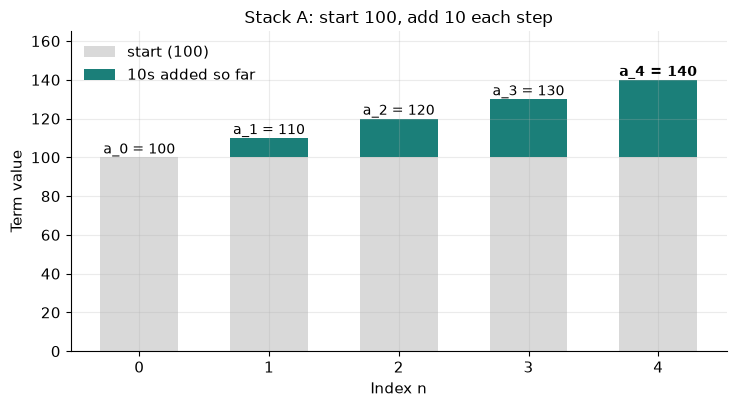

In [3]:
fig, ax = plt.subplots()
ax.bar(range(n + 1), [100] * (n + 1), width=0.6, color=LIGHT, label="start (100)")
for k in range(1, n + 1):
    ax.bar([k], [10 * k], bottom=[100], width=0.6, color=TEAL, label="10s added so far" if k == 1 else None)
for k in range(n + 1):
    ax.text(k, terms[k] + 2, f"a_{k} = {terms[k]}", ha="center", fontsize=10, fontweight="bold" if k == n else "normal")
ax.set_xticks(range(n + 1))
ax.set_ylim(0, 165)
ax.set_xlabel("Index n")
ax.set_ylabel("Term value")
ax.legend(loc="upper left", frameon=False)
show_fig("Stack A: start 100, add 10 each step")

**What this shows.** Each bar is the start of 100 plus $n$ tens. The teal part grows by one 10 per step, so $n(10)$ is exactly the teal height. Whenever a pattern adds the same amount each time, write the start and the step, then multiply the step by the number of steps.

**Where it stops working.** The rule needs the index to start at 0 and every step to add exactly 10. If even one difference changed, the list would not be steady over that stretch, and the shortcut would fail there.

## 2. Add 10 or multiply by 1.10

**Question in plain words:** Stacks A and B both begin 100, 110. Why do they part ways later?

**Equations from the chapter:**

$$b_n = 100(1.10)^n \qquad b_4 = 100(1.10)^4 = 146.41$$

**What the symbols mean:** $b_n$ is Stack B's term at index $n$. The multiplier 1.10 scales the whole current term. The exponent $n$ counts how many times the multiplier has been applied since $b_0 = 100$.

In [4]:
n = 4
a = [100 + 10 * k for k in range(n + 1)]
b = [Fraction(100) * Fraction(11, 10) ** k for k in range(n + 1)]

def fmt(x):
    # exact decimal when it ends within 6 places, otherwise rounded to 2 places and marked "about"
    for p in range(7):
        if (x * 10 ** p).denominator == 1:
            return f"{float(x):.{p}f}"
    return "about " + f"{float(x):.2f}"

print("Stack B, one multiplication at a time:")
for k in range(1, n + 1):
    print(f"  b_{k} = {fmt(b[k-1])} x 1.10 = {fmt(b[k])}   (this step added {fmt(b[k] - b[k-1])})")
print()
print(f"Stack A: a_{n} = 100 + 10({n}) = {a[-1]}")
print(f"Stack B: b_{n} = 100(1.10)^{n} = {fmt(b[-1])}")
print(f"B minus A: {fmt(b[-1])} - {a[-1]} = {fmt(b[-1] - a[-1])}")
print(f"Step added by B at the end: {fmt(b[-1] - b[-2])}.  Step added by A at every step: 10")

print()
print("Other 'last index' values from the reader's menu:")
for m in [3, 4, 10, 20]:
    am = 100 + 10 * m
    bm = Fraction(100) * Fraction(11, 10) ** m
    last = bm - Fraction(100) * Fraction(11, 10) ** (m - 1)
    print(f"  n = {m:2d}: a = 100 + 10({m}) = {am};  b = 100(1.10)^{m} = {fmt(bm)};  gap = {fmt(bm - am)};  last step of B = {fmt(last)}")

Stack B, one multiplication at a time:
  b_1 = 100 x 1.10 = 110   (this step added 10)
  b_2 = 110 x 1.10 = 121   (this step added 11)
  b_3 = 121 x 1.10 = 133.1   (this step added 12.1)
  b_4 = 133.1 x 1.10 = 146.41   (this step added 13.31)

Stack A: a_4 = 100 + 10(4) = 140
Stack B: b_4 = 100(1.10)^4 = 146.41
B minus A: 146.41 - 140 = 6.41
Step added by B at the end: 13.31.  Step added by A at every step: 10

Other 'last index' values from the reader's menu:
  n =  3: a = 100 + 10(3) = 130;  b = 100(1.10)^3 = 133.1;  gap = 3.1;  last step of B = 12.1
  n =  4: a = 100 + 10(4) = 140;  b = 100(1.10)^4 = 146.41;  gap = 6.41;  last step of B = 13.31
  n = 10: a = 100 + 10(10) = 200;  b = 100(1.10)^10 = about 259.37;  gap = about 59.37;  last step of B = about 23.58
  n = 20: a = 100 + 10(20) = 300;  b = 100(1.10)^20 = about 672.75;  gap = about 372.75;  last step of B = about 61.16


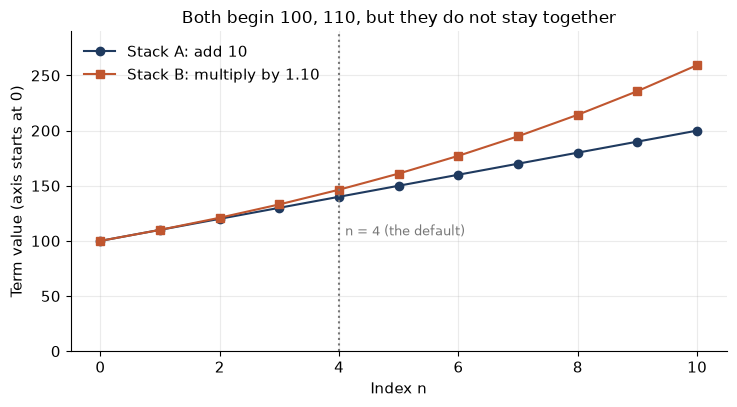

In [5]:
ks = np.arange(0, 11)
fig, ax = plt.subplots()
ax.plot(ks, 100 + 10 * ks, "o-", color=NAVY, label="Stack A: add 10")
ax.plot(ks, 100 * 1.10 ** ks, "s-", color=TERRA, label="Stack B: multiply by 1.10")
ax.axvline(4, color=GREY, linestyle=":")
ax.text(4.1, 105, "n = 4 (the default)", color=GREY, fontsize=9)
ax.set_ylim(0, 290)
ax.set_xlabel("Index n")
ax.set_ylabel("Term value (axis starts at 0)")
ax.legend(frameon=False, loc="upper left")
show_fig("Both begin 100, 110, but they do not stay together")

**What this shows.** Stack A adds the same 10 every time, so it climbs in a straight line. Stack B adds a tenth of a growing amount, so its steps grow: 10, 11, 12.1, 13.31, and on. The first few cards look close; the rules are not.

**Where it stops working.** Both rules are declared, not discovered: four cards alone do not prove how a pattern continues. The far-out values follow only if each rule really keeps going.

## 3. Where does counting start?

**Question in plain words:** The list 7, 11, 15, 19 never changes. Why can its formula change?

**Equations from the chapter:**

$$a_n = 7 + 4n \qquad\text{or}\qquad a_n = 7 + 4(n-1)$$

**What the symbols mean:** The index is the label on each card. Calling the first card $a_0$ gives the first formula. Calling it $a_1$ gives the second, where $n-1$ counts the additions since the first card. Either is fine, as long as you say which one you are using.

In [6]:
LIST = [7, 11, 15, 19]
entry = 4   # the 4th listed entry, the reader's default

print(f"The 4th entry of {LIST} is {LIST[entry-1]}.")
print()
print("Convention 1: the first entry is called a_0, rule a_n = 7 + 4n")
n0 = entry - 1
print(f"  The 4th entry has index n = {n0}")
print(f"  a_{n0} = 7 + 4({n0}) = 7 + {4*n0} = {7 + 4*n0}")
print(f"  That is {n0} additions of 4 after the starting 7.")
print()
print("Convention 2: the first entry is called a_1, rule a_n = 7 + 4(n - 1)")
n1 = entry
print(f"  The 4th entry has index n = {n1}")
print(f"  a_{n1} = 7 + 4({n1} - 1) = 7 + 4({n1-1}) = 7 + {4*(n1-1)} = {7 + 4*(n1-1)}")
print(f"  That is {n1-1} additions of 4 after the starting 7.")
print()
print("Same card, same value, two different index labels:", 7 + 4*n0 == 7 + 4*(n1-1) == LIST[entry-1])

print()
print("All four entries under both conventions:")
for e in range(1, 5):
    print(f"  entry {e}: a_{e-1} = 7 + 4({e-1}) = {7+4*(e-1)}   or   a_{e} = 7 + 4({e}-1) = {7+4*(e-1)}")

The 4th entry of [7, 11, 15, 19] is 19.

Convention 1: the first entry is called a_0, rule a_n = 7 + 4n
  The 4th entry has index n = 3
  a_3 = 7 + 4(3) = 7 + 12 = 19
  That is 3 additions of 4 after the starting 7.

Convention 2: the first entry is called a_1, rule a_n = 7 + 4(n - 1)
  The 4th entry has index n = 4
  a_4 = 7 + 4(4 - 1) = 7 + 4(3) = 7 + 12 = 19
  That is 3 additions of 4 after the starting 7.

Same card, same value, two different index labels: True

All four entries under both conventions:
  entry 1: a_0 = 7 + 4(0) = 7   or   a_1 = 7 + 4(1-1) = 7
  entry 2: a_1 = 7 + 4(1) = 11   or   a_2 = 7 + 4(2-1) = 11
  entry 3: a_2 = 7 + 4(2) = 15   or   a_3 = 7 + 4(3-1) = 15
  entry 4: a_3 = 7 + 4(3) = 19   or   a_4 = 7 + 4(4-1) = 19


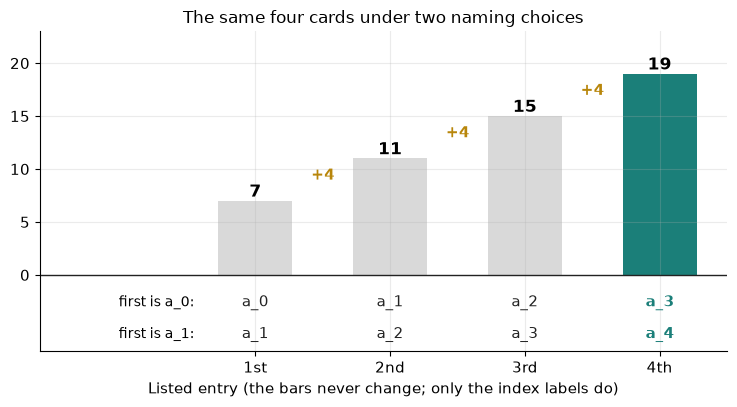

In [7]:
fig, ax = plt.subplots()
colors = [TEAL if k == entry - 1 else LIGHT for k in range(4)]
ax.bar(range(4), LIST, width=0.55, color=colors)
for k, v in enumerate(LIST):
    ax.text(k, v + 0.4, str(v), ha="center", fontsize=12, fontweight="bold")
for k in range(3):
    ax.text(k + 0.5, LIST[k] + 2, "+4", ha="center", color=GOLD, fontweight="bold")
for f0, y in [(0, -2.6), (1, -5.6)]:
    ax.text(-0.45, y, f"first is a_{f0}:", ha="right", va="center", fontsize=10)
    for k in range(4):
        ax.text(k, y, f"a_{f0 + k}", ha="center", va="center", fontsize=11,
                color=TEAL if k == entry - 1 else INK, fontweight="bold" if k == entry - 1 else "normal")
ax.axhline(0, color=INK, linewidth=1)
ax.set_xlim(-1.6, 3.5)
ax.set_ylim(-7.2, 23)
ax.set_xticks(range(4))
ax.set_xticklabels(["1st", "2nd", "3rd", "4th"])
ax.set_yticks([0, 5, 10, 15, 20])
ax.set_xlabel("Listed entry (the bars never change; only the index labels do)")
show_fig("The same four cards under two naming choices")

**What this shows.** Switching the convention relabels every card by one. The formula shifts to match, so each card's value stays put while its index moves. Write the first index beside the first value before using any direct rule. It is the cheapest way to avoid an off-by-one slip.

**Where it stops working.** This is a four-term list with difference 4. The rule with $n-1$ holds for $n$ of at least 1; using it with the $a_0$ labels would put every answer one step behind.

## 4. Ten percent keeps the whole

**Question in plain words:** A balance of 100 grows by 10% each round. What do you multiply by?

**Equations from the chapter:**

$$\text{new} = \text{previous} + 0.10(\text{previous}) \qquad 100(1.10)^3 = 133.1$$

**What the symbols mean:** *previous* is the amount before a round, *new* is the amount after it, and $0.10(\text{previous})$ is ten percent of it. Keeping the whole and adding the tenth is the same as multiplying by 1.10.

In [8]:
def fmt(x):
    x = Fraction(x)
    for p in range(7):
        if (x * 10 ** p).denominator == 1:
            return f"{float(x):.{p}f}"
    return "about " + f"{float(x):.2f}"

factor = Fraction(11, 10)      # +10 percent
terms = [Fraction(100) * factor ** k for k in range(4)]

print("Keep the whole and add a tenth:")
print(f"  100 + 0.10(100) = 100 + 10 = {fmt(terms[1])}")
print(f"  {fmt(terms[1])} + 0.10({fmt(terms[1])}) = {fmt(terms[1])} + {fmt(terms[1]/10)} = {fmt(terms[2])}")
print(f"  {fmt(terms[2])} + 0.10({fmt(terms[2])}) = {fmt(terms[2])} + {fmt(terms[2]/10)} = {fmt(terms[3])}")
print()
print("Same thing as multiplying by 1.10 each round:")
for k in range(3):
    print(f"  {fmt(terms[k])} x 1.10 = {fmt(terms[k+1])}")
print(f"Direct rule: 100(1.10)^3 = {fmt(terms[3])}")

print()
print("The other choices from the reader's menu, three rounds from 100:")
for name, f in [("+10% (x 1.10)", Fraction(11, 10)), ("mistake (x 0.10)", Fraction(1, 10)),
                ("+20% (x 1.20)", Fraction(6, 5)), ("-20% (x 0.80)", Fraction(4, 5))]:
    t = [Fraction(100) * f ** k for k in range(4)]
    chain = "; ".join(f"{fmt(t[k])} x {float(f):.2f} = {fmt(t[k+1])}" for k in range(3))
    print(f"  {name}: {chain}.  Direct: 100({float(f):.2f})^3 = {fmt(t[3])}")

Keep the whole and add a tenth:
  100 + 0.10(100) = 100 + 10 = 110
  110 + 0.10(110) = 110 + 11 = 121
  121 + 0.10(121) = 121 + 12.1 = 133.1

Same thing as multiplying by 1.10 each round:
  100 x 1.10 = 110
  110 x 1.10 = 121
  121 x 1.10 = 133.1
Direct rule: 100(1.10)^3 = 133.1

The other choices from the reader's menu, three rounds from 100:
  +10% (x 1.10): 100 x 1.10 = 110; 110 x 1.10 = 121; 121 x 1.10 = 133.1.  Direct: 100(1.10)^3 = 133.1
  mistake (x 0.10): 100 x 0.10 = 10; 10 x 0.10 = 1; 1 x 0.10 = 0.1.  Direct: 100(0.10)^3 = 0.1
  +20% (x 1.20): 100 x 1.20 = 120; 120 x 1.20 = 144; 144 x 1.20 = 172.8.  Direct: 100(1.20)^3 = 172.8
  -20% (x 0.80): 100 x 0.80 = 80; 80 x 0.80 = 64; 64 x 0.80 = 51.2.  Direct: 100(0.80)^3 = 51.2


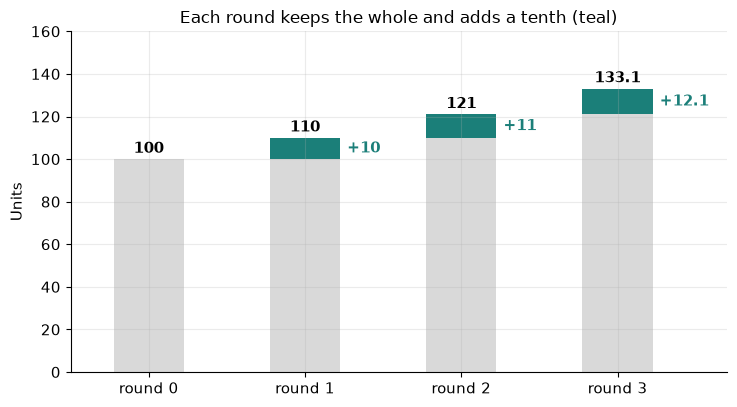

In [9]:
fig, ax = plt.subplots()
vals = [float(t) for t in terms]
for k, t in enumerate(vals):
    if k == 0:
        ax.bar([k], [t], width=0.45, color=LIGHT)
    else:
        ax.bar([k], [vals[k - 1]], width=0.45, color=LIGHT)
        ax.bar([k], [t - vals[k - 1]], bottom=[vals[k - 1]], width=0.45, color=TEAL)
        ax.text(k + 0.27, (t + vals[k - 1]) / 2, f"+{t - vals[k-1]:.4g}", color=TEAL, fontweight="bold", va="center")
    ax.text(k, t + 3, f"{t:.4g}", ha="center", fontweight="bold")
ax.set_xticks(range(4))
ax.set_xticklabels(["round 0", "round 1", "round 2", "round 3"])
ax.set_xlim(-0.5, 3.7)
ax.set_ylim(0, 160)
ax.set_ylabel("Units")
show_fig("Each round keeps the whole and adds a tenth (teal)")

**What this shows.** A multiplier above 1 grows the amount, one between 0 and 1 shrinks it, and 0.10 keeps only a tenth: that is a 90% cut, not 10% growth. Turn any percent change into a multiplier first: an increase of $p$ percent keeps the whole and adds $p$ hundredths; a decrease keeps what is left.

**Where it stops working.** The same percent must apply each round to the amount at the start of that round. If the percent were always taken from the original 100, the pattern would be steady adding instead (arithmetic), not repeated multiplying.

## Practice

**1.** Using $a_n = 100 + 10n$, what is $a_9$?

<details><summary>Show answer</summary>

$a_9 = 100 + 10(9) = 100 + 90 = 190$.

</details>

**2.** What is $b_5$ for Stack B?

<details><summary>Show answer</summary>

Step by step: $b_4 = 146.41$, so $b_5 = 146.41 \times 1.10 = 161.051$. Direct rule: $100(1.10)^5 = 161.051$. The two agree.

</details>

**3.** A 20% decrease is applied twice to 100. What remains?

<details><summary>Show answer</summary>

A 20% decrease keeps 80%, so the multiplier is 0.8. $100(0.8)(0.8) = 100(0.64) = 64$, so 64% of the start remains. (Not 60: the second cut is taken from 80, not from 100.)

</details>

**Bonus.** With the first entry of 7, 11, 15, 19 called $a_1$, what is $a_6$?

<details><summary>Show answer</summary>

$a_6 = 7 + 4(6 - 1) = 7 + 4(5) = 7 + 20 = 27$.

</details>